# №6. Свёртка

Цель: реализовать свёртку, равномерное и гауссово сглаживание.
Для цветного изображения каждый канал обрабатывается отдельно.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
plt.rcParams['image.interpolation'] = 'nearest'


def to_uint8(image):
    return np.clip(np.rint(image), 0, 255).astype(np.uint8)


def show_images(images, titles, cols=3, figsize=None):
    rows = (len(images) + cols - 1) // cols
    figsize = figsize or (4 * cols, 3.2 * rows)
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, image, title in zip(axes.flat, images, titles):
        if image.ndim == 2:
            ax.imshow(image, vmin=0, vmax=255)
        else:
            ax.imshow(to_uint8(image))
        ax.set_title(title)
    fig.tight_layout()
    plt.show()

## 1. Функция свёртки

$$g[y,x]=\sum_i\sum_j K[i,j]\,f[y-(i-r_y),\,x-(j-r_x)].$$

Скользящее окно удобно умножать на перевёрнутое ядро `kernel[::-1, ::-1]`.
Края продолжаются зеркально (`reflect`). Расчёты идут в `float64`;
округление до `uint8` применяется при показе.

In [3]:
def convolve(image, kernel):
    """Дискретная свёртка с сохранением размера изображения."""
    source = np.asarray(image, dtype=float)
    kernel = np.asarray(kernel, dtype=float)
    kh, kw = kernel.shape
    h, w = source.shape[:2]
    pad = ((kh // 2, kh // 2), (kw // 2, kw // 2))
    if source.ndim == 3:
        pad += ((0, 0),)
    padded = np.pad(source, pad, mode="reflect")
    flipped = kernel[::-1, ::-1]
    result = np.zeros_like(source)
    for i in range(kh):
        for j in range(kw):
            result += flipped[i, j] * padded[i:i + h, j:j + w]
    return result


def box_kernel(size):
    return np.full((size, size), 1.0 / size**2)


def gaussian_kernel(size, sigma):
    coordinates = np.arange(size) - size // 2
    y, x = np.meshgrid(coordinates, coordinates, indexing="ij")
    kernel = np.exp(-(x*x + y*y) / (2 * sigma*sigma))
    return kernel / kernel.sum()

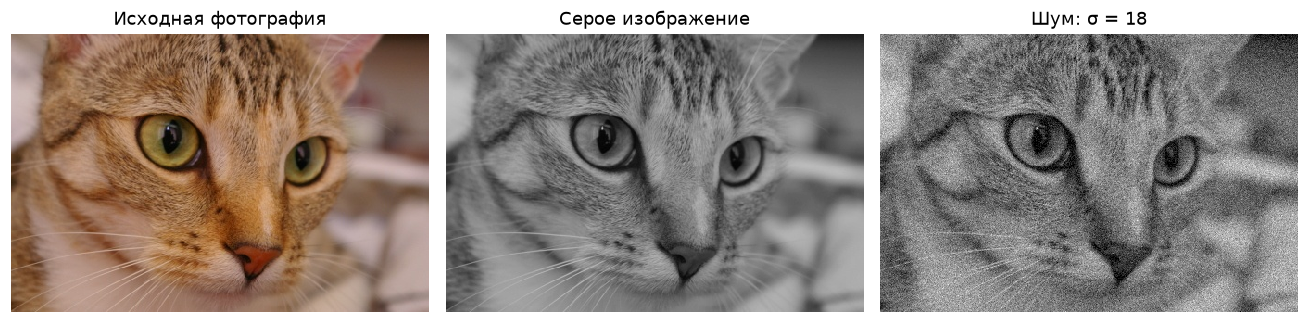

In [4]:
image = np.array(Image.open("data/scene.jpg").convert("RGB"))
gray = image.astype(float) @ np.array([0.2126, 0.7152, 0.0722])
rng = np.random.default_rng(42)
noisy = np.clip(gray + rng.normal(0, 18, gray.shape), 0, 255)
show_images([image, to_uint8(gray), to_uint8(noisy)],
            ["Исходная фотография", "Серое изображение", "Шум: σ = 18"])

## 2. Постоянные ядра

В окне $w\times w$ каждый вес равен $1/w^2$. Сумма весов равна единице,
поэтому постоянная яркость сохраняется.

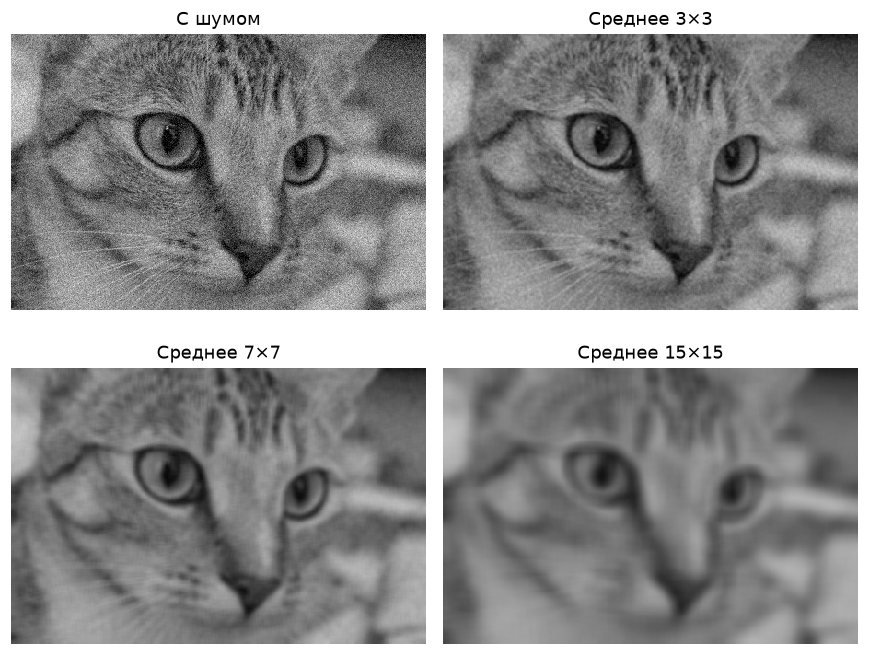

Окно  3: сумма ядра = 1.000000, RMSE = 8.02
Окно  7: сумма ядра = 1.000000, RMSE = 9.25
Окно 15: сумма ядра = 1.000000, RMSE = 13.29


In [5]:
box_sizes = [3, 7, 15]
box_results = [convolve(noisy, box_kernel(size)) for size in box_sizes]
show_images([to_uint8(noisy), *[to_uint8(a) for a in box_results]],
            ["С шумом", *[f"Среднее {size}×{size}" for size in box_sizes]], cols=2)
for size, result in zip(box_sizes, box_results):
    print(f"Окно {size:2d}: сумма ядра = {box_kernel(size).sum():.6f}, "
          f"RMSE = {np.sqrt(np.mean((result - gray)**2)):.2f}")

## 3. Гауссовы ядра

$$K[i,j]=C\exp\left[-\frac{i^2+j^2}{2\sigma^2}\right],\qquad \sum K=1.$$

$\sigma$ задаёт ширину распределения весов; размер окна ограничивает его поддержку.
Для сравнения меняем каждый параметр отдельно.

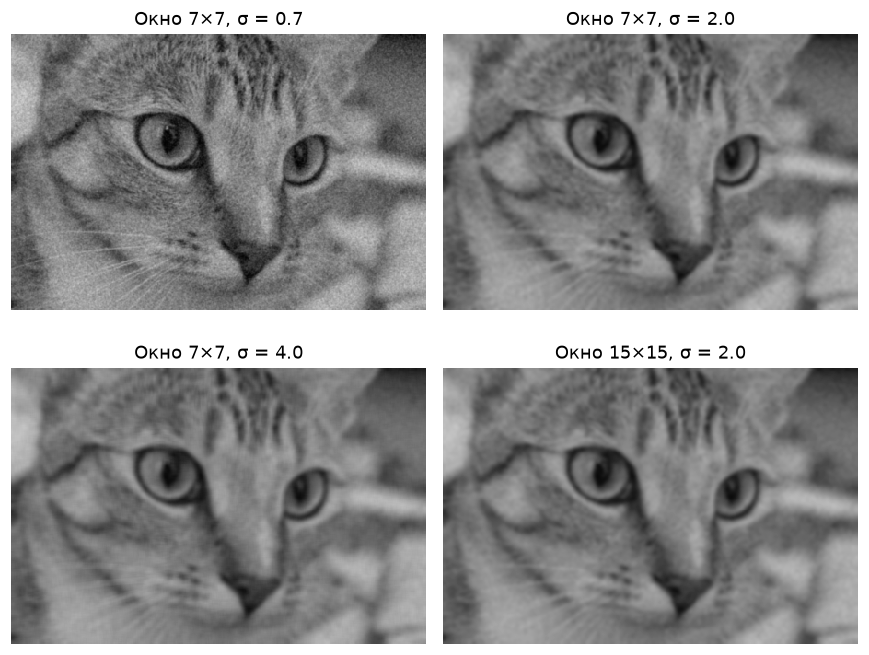

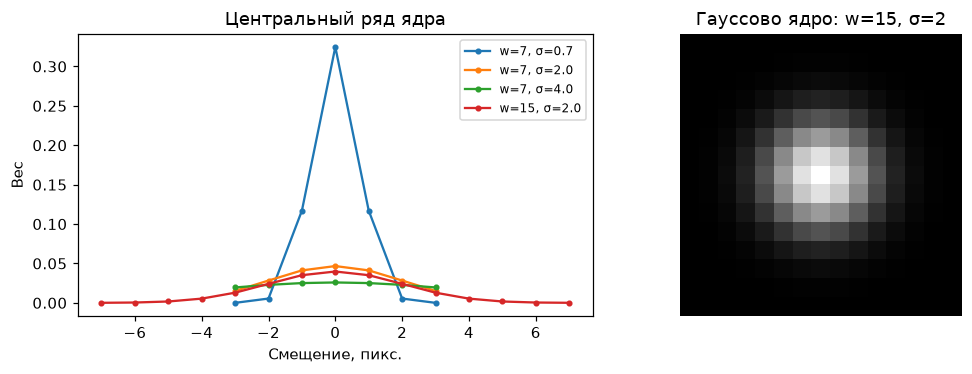

w= 7, σ=0.7: RMSE = 8.30
w= 7, σ=2.0: RMSE = 8.19
w= 7, σ=4.0: RMSE = 8.94
w=15, σ=2.0: RMSE = 8.54


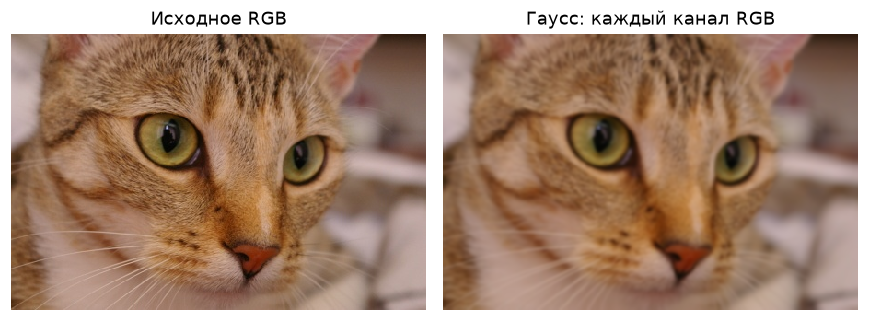

In [6]:
parameters = [(7, 0.7), (7, 2.0), (7, 4.0), (15, 2.0)]
gaussian_results = [convolve(noisy, gaussian_kernel(size, sigma))
                    for size, sigma in parameters]
show_images([to_uint8(a) for a in gaussian_results],
            [f"Окно {size}×{size}, σ = {sigma}" for size, sigma in parameters], cols=2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for size, sigma in parameters:
    kernel = gaussian_kernel(size, sigma)
    coordinates = np.arange(size) - size // 2
    axes[0].plot(coordinates, kernel[size // 2], marker=".", label=f"w={size}, σ={sigma}")
axes[0].set(xlabel="Смещение, пикс.", ylabel="Вес", title="Центральный ряд ядра")
axes[0].legend(fontsize=8)
axes[1].imshow(gaussian_kernel(15, 2.0), cmap="gray")
axes[1].set_title("Гауссово ядро: w=15, σ=2")
axes[1].set_axis_off()
fig.tight_layout()
plt.show()

for (size, sigma), result in zip(parameters, gaussian_results):
    print(f"w={size:2d}, σ={sigma:3.1f}: RMSE = {np.sqrt(np.mean((result - gray)**2)):.2f}")

show_images([image, to_uint8(convolve(image, gaussian_kernel(9, 1.5)))],
            ["Исходное RGB", "Гаусс: каждый канал RGB"], cols=2)

## Вывод

Равномерное ядро даёт одинаковый вес всем пикселям окна. Гауссово ядро усиливает
вклад центра и плавно уменьшает вклад краёв. Рост окна и σ расширяет область
сглаживания: шум ослабевает, мелкие детали и резкие границы размываются.
RMSE на выбранной фотографии помогает подобрать степень сглаживания.